[Megnyitás a Google Colabban](https://colab.research.google.com/github/ComplexSystemsIntelligence/biztonsagkritikus-rendszerek/blob/main/gyakorlat/notebookok/04_fmeda.ipynb) · *Biztonságkritikus rendszerek – gyakorlati útmutató* · © 2026 Abonyi János, Pannon Egyetem · kód: MIT, szöveg: CC BY-NC-SA 4.0

# 4. gyakorlat – FMEDA: diagnosztikai lefedettség és biztonságos meghibásodási hányad

A notebook a könyv 6. fejezetének TT-101 hőmérséklet-távadójára számolja ki az FMEDA-mérőszámokat, majd megmutatja, hogyan változik a DC és az SFF a diagnosztika fejlesztésével.

**Tanulási eredmények:** FMEDA-táblázatból $\lambda_S$, $\lambda_{DD}$, $\lambda_{DU}$, DC és SFF számolása; a diagnosztikai fejlesztések hatásának értékelése; a mérőszámok kapcsolata az architekturális korlátokkal.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
PE = {"kek": "#285780", "sotet": "#1B3A57", "kiemel": "#E07B39", "zold": "#3E8E63", "piros": "#B83A3A", "lila": "#7A5C99", "szurke": "#6B7280"}
plt.rcParams.update({"figure.figsize": (7.5, 4.2), "axes.grid": True, "grid.color": "#e6e9ee", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.prop_cycle": plt.cycler(color=list(PE.values())), "axes.formatter.use_locale": False})
def hu(x, sig=3):
    """Szám magyar formátumban (tizedesvessző, normálalak)."""
    if x == 0: return "0"
    e = int(np.floor(np.log10(abs(x))))
    if -2 <= e < 5: return f"{x:.{max(0, sig-1-e)}f}".replace(".", ",")
    return f"{x/10**e:.{sig-1}f}".replace(".", ",") + f"·10^{e}"
import pandas as pd

In [2]:
# blokk, meghibásodási mód, λ [FIT], kategória (S / D), diagnosztikai lefedettség a veszélyes részre
fmeda = pd.DataFrame([
    ("RTD érzékelőelem", "szakadás", 150, "S", 0.0),
    ("RTD érzékelőelem", "rövidzár", 100, "D", 1.0),
    ("RTD érzékelőelem", "lassú drift lefelé", 250, "D", 0.0),
    ("A/D átalakító", "befagyott vagy hibás érték", 200, "D", 0.7),
    ("mikrovezérlő", "programfutási hiba", 300, "D", 0.9),
    ("kimeneti fokozat", "áram a felső határon", 200, "S", 0.0),
    ("kimeneti fokozat", "áram beragad közbenső értéken", 150, "D", 0.6),
    ("tápegység", "kiesés", 150, "S", 0.0)],
    columns=["blokk", "mód", "lambda_FIT", "kat", "dc"])
def merok(df):
    lS = df.loc[df.kat == "S", "lambda_FIT"].sum()
    D = df[df.kat == "D"]
    lDD = (D.lambda_FIT * D.dc).sum(); lDU = (D.lambda_FIT * (1 - D.dc)).sum()
    return dict(lS=lS, lDD=lDD, lDU=lDU, DC=lDD/(lDD+lDU), SFF=(lS+lDD)/(lS+lDD+lDU))
m = merok(fmeda)
print(f"λS = {m['lS']:.0f} FIT, λDD = {m['lDD']:.0f} FIT, λDU = {m['lDU']:.0f} FIT")
print(f"DC = {100*m['DC']:.1f} %, SFF = {100*m['SFF']:.1f} %")

λS = 500 FIT, λDD = 600 FIT, λDU = 400 FIT
DC = 60.0 %, SFF = 73.3 %


Az eredmény egyezik a könyv 6.x táblázatával: $\lambda_D = 1000$ FIT, DC = 60%, SFF = 73,3%. A legnagyobb rejtett veszélyes hozzájárulás az érzékelőelem driftje.

## Diagnosztikai fejlesztések

Vizsgáljunk három lehetséges fejlesztést: (a) a két távadó jelének eltérésfigyelése a logikában, amely a drift 90%-át felfedi; (b) jobb A/D-referenciaellenőrzés (95%); (c) mindkettő.

                       lDD    lDU  DC_%  SFF_%
alap                 600.0  400.0  60.0   73.3
(a) eltérésfigyelés  825.0  175.0  82.5   88.3
(b) A/D-referencia   650.0  350.0  65.0   76.7
(c) mindkettő        875.0  125.0  87.5   91.7


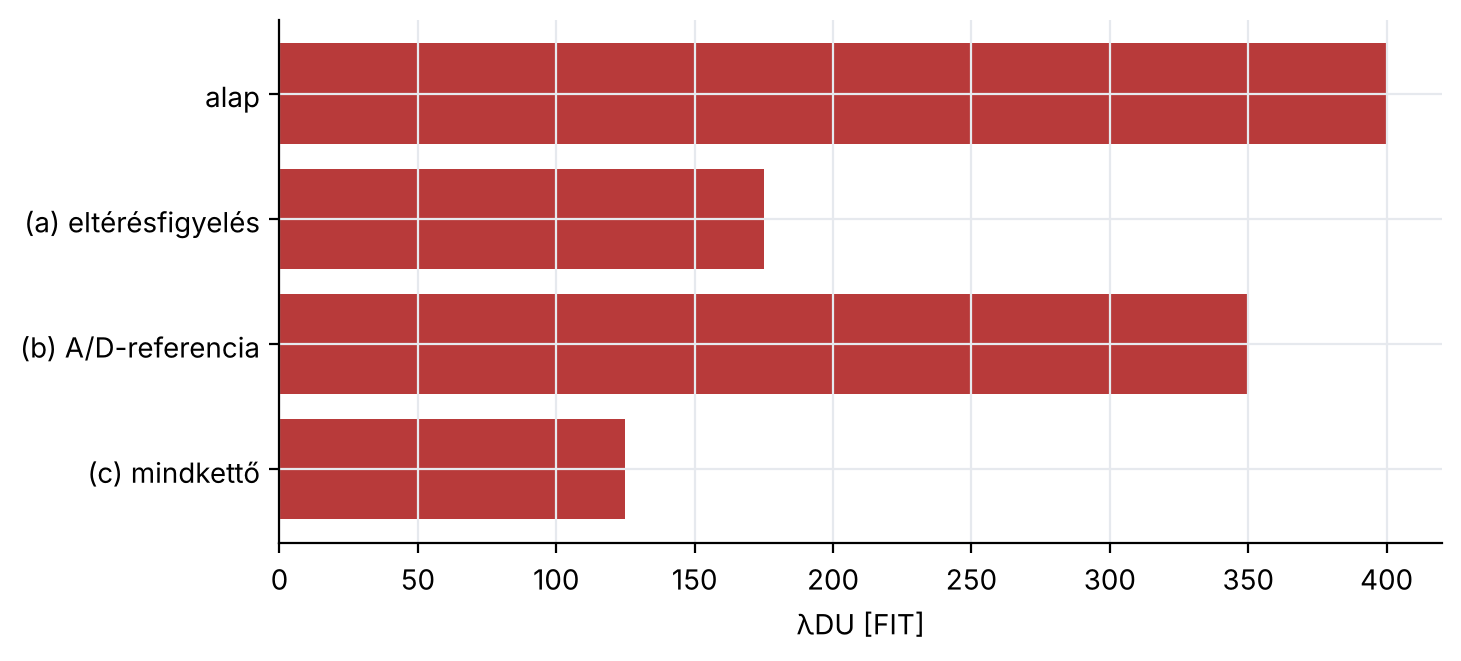

In [3]:
valtozatok = {"alap": {}, "(a) eltérésfigyelés": {2: 0.9}, "(b) A/D-referencia": {3: 0.95}, "(c) mindkettő": {2: 0.9, 3: 0.95}}
eredm = {}
for nev, mod in valtozatok.items():
    df = fmeda.copy()
    for i, dc in mod.items(): df.loc[i, "dc"] = dc
    eredm[nev] = merok(df)
tab = pd.DataFrame(eredm).T
tab["DC_%"] = 100*tab.DC; tab["SFF_%"] = 100*tab.SFF
print(tab[["lDD", "lDU", "DC_%", "SFF_%"]].round(1))
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.barh(list(tab.index), tab.lDU, color=PE["piros"]); ax.set_xlabel("λDU [FIT]"); ax.invert_yaxis(); plt.show()

**Értelmezés.** Az eltérésfigyelés a rejtett veszélyes rátát 400 FIT-ről 175 FIT-re csökkenti (SFF = 88,3%); a két fejlesztés együtt az SFF-et 90% fölé emeli (91,7%). Az IEC 61508 1H útja szerint egy B típusú elem HFT = 0 mellett 90–99% közötti SFF-fel már SIL 2-ig alkalmazható (60–90% között csak SIL 1-ig). A diagnosztika tehát nemcsak a PFD-t javítja, hanem az architekturális korlátot is.

**1. feladat.** Számold ki a TT-101 egycsatornás PFD-jét ($T_1 = 8760$ h, MTTR = 8 h) az alapváltozatra és a (c) változatra!

**2. feladat.** Egy gyártó a „nincs hatás” kategóriájú meghibásodásokat is a biztonságosak közé számolná, és így az SFF 80% fölé kerülne. Miért nem fogadható ez el az IEC 61508 2010-es kiadása szerint?

In [4]:
# 1. feladat
T1, MTTR = 8760, 8
for nev in ["alap", "(c) mindkettő"]:
    lDU, lDD = eredm[nev]["lDU"]*1e-9, eredm[nev]["lDD"]*1e-9
    print(nev, hu(lDU*(T1/2+MTTR) + lDD*MTTR))

alap 1,76·10^-3
(c) mindkettő 5,55·10^-4
